In [4]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from google.colab import files

In [ ]:
uploaded = files.upload()
input_name = next(iter(uploaded))
input_path = '/content/' + input_name

print('Input Image:', input_name)

Saving matn.png to matn.png
Input Image: matn.png


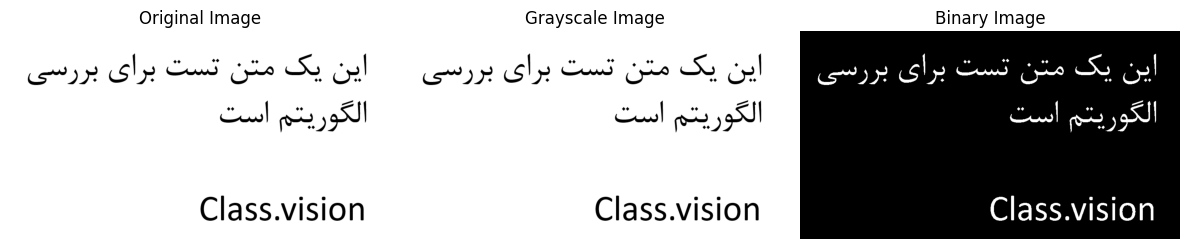

In [ ]:
input_image = cv2.imread(input_path)
if input_image is None:
  raise ValueError('Invalid Image Path')

gray_image = cv2.cvtColor(input_image, cv2.COLOR_BGR2GRAY)

_, binary_image = cv2.threshold(gray_image, 127, 255, cv2.THRESH_BINARY_INV)

plt.figure(figsize=(12, 8))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(input_image, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(gray_image, cmap='gray')
plt.title('Grayscale Image')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(binary_image, cmap='gray')
plt.title('Binary Image')
plt.axis('off')

plt.tight_layout()
plt.show()

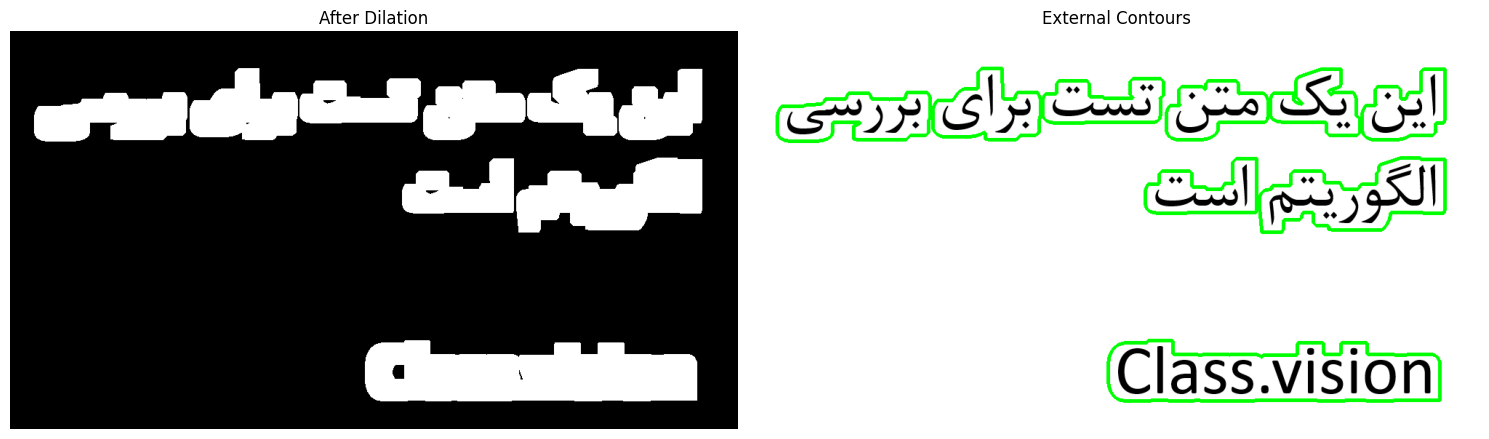

In [5]:
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 10))

dilation = cv2.dilate(binary_image, kernel, iterations=2)

contours, hierarchy = cv2.findContours(dilation, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

contours_image = input_image.copy()
cv2.drawContours(contours_image, contours, -1, (0, 255, 0), 3)

plt.figure(figsize=(15, 8))

plt.subplot(1, 2, 1)
plt.imshow(dilation, cmap='gray')
plt.title('After Dilation')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(contours_image, cv2.COLOR_BGR2RGB))
plt.title('External Contours')
plt.axis('off')

plt.tight_layout()
plt.show()

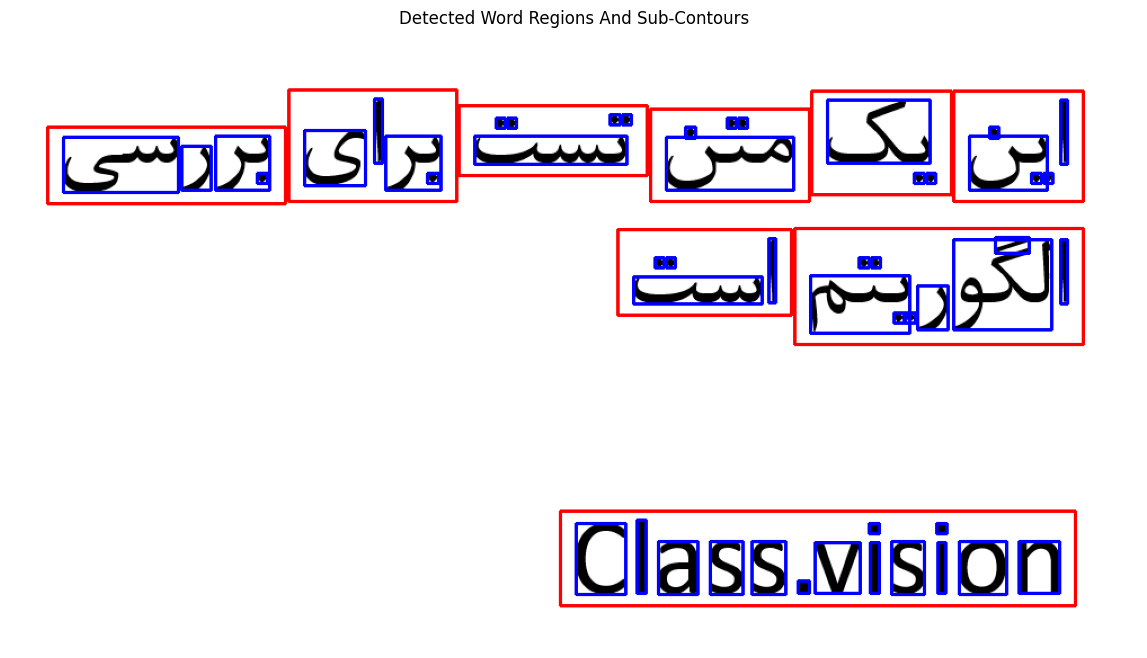

In [7]:
MIN_CONTOUR_AREA = 5
output_image = input_image.copy()
valid_contours = 0

for contour in contours:
  contour_area = cv2.contourArea(contour)

  if contour_area <= MIN_CONTOUR_AREA:
    continue

  x, y, width, height = cv2.boundingRect(contour)
  valid_contours += 1

  cv2.rectangle(output_image, (x, y), (x + width, y + height), (0, 0, 255), 2)

  word_roi = binary_image[y:y + height, x:x + width]
  sub_contours, sub_hierarchy = cv2.findContours(word_roi.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

  for sub_contour in sub_contours:
    point_x, point_y, sub_width, sub_height = cv2.boundingRect(sub_contour)

    cv2.rectangle(output_image, (x + point_x, y + point_y), (x + point_x + sub_width, y + point_y + sub_height), (255, 0, 0), 2)

plt.figure(figsize=(15, 8))

plt.imshow(cv2.cvtColor(output_image, cv2.COLOR_BGR2RGB))
plt.title('Detected Word Regions And Sub-Contours')
plt.axis('off')

plt.show()

In [8]:
output_images = {
    'matn_binary.png': binary_image,
    'matn_dilation.png': dilation,
    'matn_external_contours.png': contours_image,
    'matn_word_regions.png': output_image,
}

for filename, output_image in output_images.items():
  output_path = f'/content/{filename}_output.png'
  cv2.imwrite(output_path, output_image)
  print(f'Saved: {output_path}')
  files.download(output_path)
  print(f'Downloaded: {output_path}')

Saved: /content/matn_binary.png_output.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: /content/matn_binary.png_output.png
Saved: /content/matn_dilation.png_output.png


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

Downloaded: /content/matn_external_contours.png_output.png
Saved: /content/matn_word_regions.png_output.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: /content/matn_word_regions.png_output.png
